# Scary Stochastics, Week 5: Thompson Sampling
## Notebook 3 of 3 — The System and the Classifiers

Self-contained again. This notebook zooms out: how the pieces of the simulation fit together, how storing the town differently changes speed, and what we can learn from the logs of 1,500 vampire lives by training two classifiers: **which kind of victim was that?** and **how likely is the hunter tonight?**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Vampire palette (extends the series palette with blood burgundy, midnight indigo and ivory)
PALETTE = {
    "burgundy": "#7A0C1E",  # blood burgundy - the Thompson Sampling vampire
    "indigo":   "#232A5C",  # midnight indigo
    "ivory":    "#FFFFF0",  # ivory - plot panels and light text
    "red":      "#C8102E",
    "orange":   "#E8741C",
    "rust":     "#B5451B",
    "purple":   "#3B2145",
    "mustard":  "#D9A404",
    "teal":     "#2A7F7F",
    "silver":   "#9AA5B4",
    "blue":     "#4682B4",
    "black":    "#1B1B1B",
    "cream":    "#FBF3E1",
}

plt.rcParams.update({
    "figure.facecolor": PALETTE["cream"],
    "axes.facecolor": PALETTE["ivory"],
    "axes.edgecolor": PALETTE["black"],
    "text.color": PALETTE["black"],
    "axes.labelcolor": PALETTE["black"],
    "xtick.color": PALETTE["black"],
    "ytick.color": PALETTE["black"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

In [2]:
# ---------------------------------------------------------------------------
# The town and its seven victim classes
# ---------------------------------------------------------------------------
CLASSES = ["Night Nurse", "Town Drunk", "Grandma", "Insomniac", "College Student", "Priest", "Sleepwalker"]
DISTS = ["Poisson(5)", "Normal(7, 2)", "Pareto(1.5)", "Gamma(2, 2)", "Poisson(10)", "Gamma(1, 1)", "Log-normal"]
CLASS_COLORS = [PALETTE["blue"], PALETTE["mustard"], PALETTE["rust"], PALETTE["purple"],
                PALETTE["orange"], PALETTE["silver"], PALETTE["teal"]]

K = 7                  # victim classes in town
N_NIGHTLY = 5          # classes on offer each night
TOWN_SIZE = 2500       # people in town: the hunter is 1 in 2,500 on a calm night
WARY_SCALE = 450.0     # every 450 pints drained adds +1 to the town's wariness
HAZARD_CAP = 0.05      # hunter chance per bite never exceeds 5%

PAR_ALPHA, PAR_XM = 1.5, 2.0      # Grandma: Pareto tail index and minimum yield
LN_MU, LN_SIGMA = 1.4, 0.7        # Sleepwalker: log-normal parameters
CAP = 40.0                        # cap on a sampled "expected yield" (Pareto can have a huge mean)

# Rates are "rate" (not "scale") for the Gamma classes, so Gamma(2, 2) averages 1 pint
TRUE_MEAN = np.array([5.0, 7.0, PAR_ALPHA * PAR_XM / (PAR_ALPHA - 1), 1.0, 10.0, 1.0,
                      np.exp(LN_MU + LN_SIGMA ** 2 / 2)])

def draw_yield(arm, rng):
    """Pints of blood from one bite on each vampire's chosen class (arm is an int array)."""
    y = np.empty(len(arm))
    for c in range(K):
        m = arm == c
        k = int(m.sum())
        if k == 0:
            continue
        if c == 0:   y[m] = rng.poisson(5.0, k)
        elif c == 1: y[m] = np.maximum(rng.normal(7.0, 2.0, k), 0)
        elif c == 2: y[m] = PAR_XM * (1 + rng.pareto(PAR_ALPHA, k))   # classic Pareto
        elif c == 3: y[m] = rng.gamma(2.0, 1 / 2.0, k)
        elif c == 4: y[m] = rng.poisson(10.0, k)
        elif c == 5: y[m] = rng.gamma(1.0, 1 / 1.0, k)
        else:        y[m] = rng.lognormal(LN_MU, LN_SIGMA, k)
    return y

# ---------------------------------------------------------------------------
# The vampire's beliefs: one conjugate posterior per class.
# n = bites so far, s = total pints, sl = total log-yield (Pareto: log(y / min yield))
# ---------------------------------------------------------------------------
def posterior_mean_draw(n, s, sl, rng):
    """One random draw of each class's EXPECTED yield from the vampire's current beliefs."""
    out = np.empty(n.shape)
    for c in (0, 4):   # Poisson classes: Gamma belief on the rate
        out[..., c] = rng.gamma(1.0 + s[..., c], 1.0 / (0.1 + n[..., c]))
    prec = 1 / 10.0 ** 2 + n[..., 1] / 2.0 ** 2    # Town Drunk: Normal belief on the mean (SD known)
    mean = (5.0 / 10.0 ** 2 + s[..., 1] / 2.0 ** 2) / prec
    out[..., 1] = rng.normal(mean, 1 / np.sqrt(prec))
    alpha = rng.gamma(1.0 + n[..., 2], 1.0 / (0.5 + sl[..., 2]))   # Grandma: Gamma belief on the tail index
    out[..., 2] = np.where(alpha > 1.05,
                           np.minimum(alpha * PAR_XM / np.maximum(alpha - 1, 1e-9), CAP), CAP)
    for c, shape in ((3, 2.0), (5, 1.0)):      # Gamma classes: Gamma belief on the rate (shape known)
        beta = rng.gamma(2.0 + shape * n[..., c], 1.0 / (1.0 + s[..., c]))
        out[..., c] = np.minimum(shape / beta, CAP)
    prec = 1 / 2.0 ** 2 + n[..., 6] / LN_SIGMA ** 2    # Sleepwalker: Normal belief on the log-scale mean
    mean = (1.0 / 2.0 ** 2 + sl[..., 6] / LN_SIGMA ** 2) / prec
    out[..., 6] = np.exp(rng.normal(mean, 1 / np.sqrt(prec)) + LN_SIGMA ** 2 / 2)
    return out

def pol_ts(n, s, sl, t, rng):
    """Thompson Sampling: score each class by one random draw from its posterior."""
    return posterior_mean_draw(n, s, sl, rng)

# ---------------------------------------------------------------------------
# The simulator: many vampires hunt in parallel (one row per vampire)
# ---------------------------------------------------------------------------
def simulate(policy, R, T, seed, hunter=False, snap=()):
    rng = np.random.default_rng(seed)
    n, s, sl = np.zeros((R, K)), np.zeros((R, K)), np.zeros((R, K))
    alive, drained, rows = np.ones(R, bool), np.zeros(R), np.arange(R)
    arm_log = np.full((R, T), -1, dtype=np.int8)
    y_log = np.zeros((R, T), dtype=np.float32)
    drained_log = np.zeros((R, T), dtype=np.float32)
    alive_log = np.zeros((R, T), dtype=bool)
    died_log = np.zeros((R, T), dtype=bool)
    regret = np.zeros((R, T))
    snaps = {}
    for t in range(T):
        if not alive.any():
            break
        # Five of the seven classes are on offer tonight (a fresh random five per vampire)
        cmask = np.zeros((R, K), bool)
        np.put_along_axis(cmask, np.argsort(rng.random((R, K)), axis=1)[:, :N_NIGHTLY], True, axis=1)
        arm = np.where(cmask, policy(n, s, sl, t, rng), -np.inf).argmax(axis=1)
        y = draw_yield(arm, rng)
        best = np.where(cmask, TRUE_MEAN, -np.inf).max(axis=1)
        # The hunter: 1 in TOWN_SIZE per bite, multiplied by the town's wariness
        wariness = 1 + drained / WARY_SCALE
        died = np.zeros(R, bool)
        if hunter:
            died = alive & (rng.random(R) < np.minimum(wariness / TOWN_SIZE, HAZARD_CAP))
        bite = alive & ~died
        idx, a, yy = rows[bite], arm[bite], y[bite]
        lg = np.log(np.maximum(yy, 1e-9))
        n[idx, a] += 1
        s[idx, a] += yy
        sl[idx, a] += np.where(a == 2, lg - np.log(PAR_XM), lg)
        arm_log[:, t] = np.where(alive, arm, -1)
        y_log[:, t] = np.where(bite, y, 0)
        drained_log[:, t] = drained
        alive_log[:, t] = alive
        died_log[:, t] = died
        regret[:, t] = np.where(alive, best - TRUE_MEAN[arm], 0)
        drained = drained + np.where(bite, y, 0)
        alive = bite
        if (t + 1) in snap:
            snaps[t + 1] = (n.copy(), s.copy(), sl.copy())
    return {"arm": arm_log, "y": y_log, "drained": drained_log, "alive": alive_log,
            "died": died_log, "regret": regret, "snaps": snaps}

In [3]:
# ---------------------------------------------------------------------------
# Rival vampires (each returns one score per class; the vampire bites the highest)
# ---------------------------------------------------------------------------
def pol_random(n, s, sl, t, rng):
    return rng.random(n.shape)

def pol_greedy(n, s, sl, t, rng):
    """Always bite the class with the best average so far (untried classes get tried first)."""
    avg = s / np.maximum(n, 1)
    return np.where(n > 0, avg, 1e6) + 1e-6 * rng.random(n.shape)

def pol_eps(n, s, sl, t, rng):
    """Greedy, but 10% of nights bite a random class."""
    explore = rng.random(n.shape[0]) < 0.10
    return np.where(explore[:, None], rng.random(n.shape), pol_greedy(n, s, sl, t, rng))

def pol_ucb(n, s, sl, t, rng):
    """Average plus an 'optimism bonus' that shrinks as a class gets bitten more."""
    avg = s / np.maximum(n, 1)
    bonus = 4.0 * np.sqrt(np.log(t + 2) / np.maximum(n, 1))
    return np.where(n > 0, avg + bonus, 1e6 + rng.random(n.shape))

def pol_gauss_ts(n, s, sl, t, rng):
    """Thompson Sampling that wrongly assumes every class is Normal with the same spread."""
    return rng.normal((6.0 + s) / (n + 1), 4.0 / np.sqrt(n + 1))

def pol_oracle(n, s, sl, t, rng):
    """Knows every class's true average from night one (the benchmark for regret)."""
    return np.tile(TRUE_MEAN, (n.shape[0], 1))

POLICIES = {"Random": pol_random, "Greedy": pol_greedy, "Epsilon-Greedy": pol_eps,
            "UCB": pol_ucb, "Gaussian TS": pol_gauss_ts, "Thompson Sampling": pol_ts}
POLICY_COLORS = {"Random": PALETTE["silver"], "Greedy": PALETTE["purple"],
                 "Epsilon-Greedy": PALETTE["orange"], "UCB": PALETTE["mustard"],
                 "Gaussian TS": PALETTE["teal"], "Thompson Sampling": PALETTE["burgundy"]}

### Visual 9 — System architecture

One night in the pipeline. Candidates are drawn from the town, the belief engine turns each class's history into a random draw, the vampire bites the highest, the hunter check runs, and the result flows two ways: back into the beliefs, and into a log that the classifiers train on.

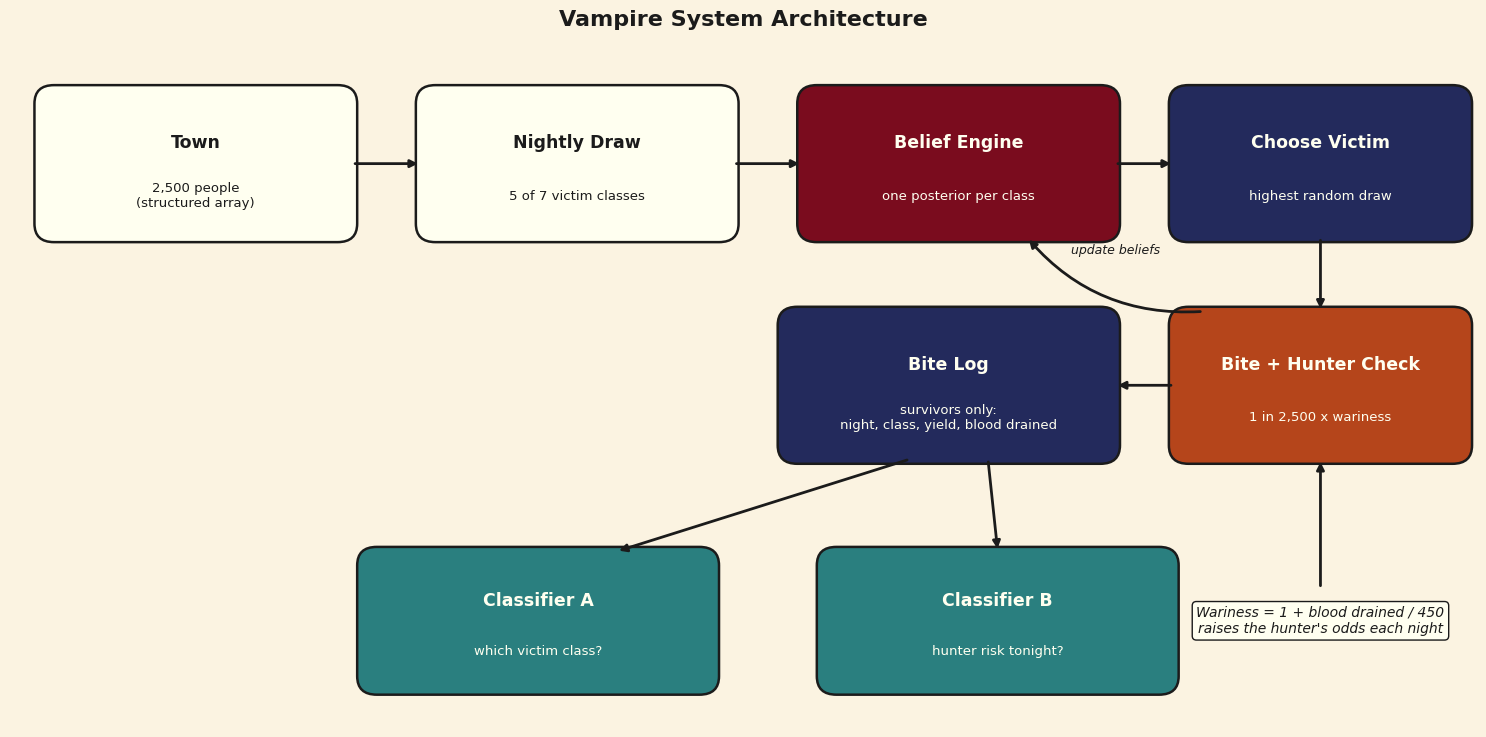

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set_xlim(0, 15); ax.set_ylim(0, 7.5); ax.axis("off")

def box(x, y, w, h, title, sub, fill, text):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.2",
                                facecolor=fill, edgecolor=PALETTE["black"], linewidth=1.8))
    ax.text(x + w / 2, y + h * 0.64, title, ha="center", va="center", fontsize=12.5,
            fontweight="bold", color=text)
    ax.text(x + w / 2, y + h * 0.28, sub, ha="center", va="center", fontsize=9.5, color=text)

def arrow(x0, y0, x1, y1, label="", rad=0.0):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=PALETTE["black"], linewidth=2,
                                connectionstyle=f"arc3,rad={rad}"))
    if label:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.22, label, ha="center", fontsize=9, style="italic")

ivory, dark = PALETTE["ivory"], PALETTE["ivory"]
box(0.3, 5.3, 3.2, 1.6, "Town", "2,500 people\n(structured array)", ivory, PALETTE["black"])
box(4.2, 5.3, 3.2, 1.6, "Nightly Draw", "5 of 7 victim classes", ivory, PALETTE["black"])
box(8.1, 5.3, 3.2, 1.6, "Belief Engine", "one posterior per class", PALETTE["burgundy"], dark)
box(11.9, 5.3, 3.0, 1.6, "Choose Victim", "highest random draw", PALETTE["indigo"], dark)
box(11.9, 2.9, 3.0, 1.6, "Bite + Hunter Check", "1 in 2,500 x wariness", PALETTE["rust"], dark)
box(7.9, 2.9, 3.4, 1.6, "Bite Log", "survivors only:\nnight, class, yield, blood drained", PALETTE["indigo"], dark)
box(3.6, 0.4, 3.6, 1.5, "Classifier A", "which victim class?", PALETTE["teal"], dark)
box(8.3, 0.4, 3.6, 1.5, "Classifier B", "hunter risk tonight?", PALETTE["teal"], dark)

arrow(3.5, 6.1, 4.2, 6.1)
arrow(7.4, 6.1, 8.1, 6.1)
arrow(11.3, 6.1, 11.9, 6.1)
arrow(13.4, 5.3, 13.4, 4.5)
arrow(11.9, 3.7, 11.3, 3.7)
arrow(12.2, 4.5, 10.4, 5.3, "update beliefs", rad=-0.25)
arrow(9.2, 2.9, 6.2, 1.9)
arrow(10.0, 2.9, 10.1, 1.9)
ax.text(13.4, 1.15, "Wariness = 1 + blood drained / 450\nraises the hunter's odds each night",
        ha="center", va="center", fontsize=10, style="italic",
        bbox=dict(boxstyle="round", facecolor=PALETTE["ivory"], edgecolor=PALETTE["black"]))
arrow(13.4, 1.5, 13.4, 2.9)
ax.set_title("Vampire System Architecture", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("09_system_architecture.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 10 — How should the town be stored?

The same 2,500 townspeople, stored three ways: a **list of Python objects**, a NumPy **structured array** (an *array of structures*: one record per person), and a **dict of arrays** (a *structure of arrays*: one array per field). We time a column scan (average bites among Insomniacs) at two town sizes, and a record update (five victims bitten).

Read the results with care: the big gap between Python objects and NumPy is mostly Python overhead. The array-of-structures vs. structure-of-arrays gap is the memory-layout effect, and it only starts to show once the town is big enough not to fit in cache. For the tiny five-victim update, plain Python objects can win outright, because NumPy's fixed per-call overhead dwarfs the work. Absolute times vary by machine.

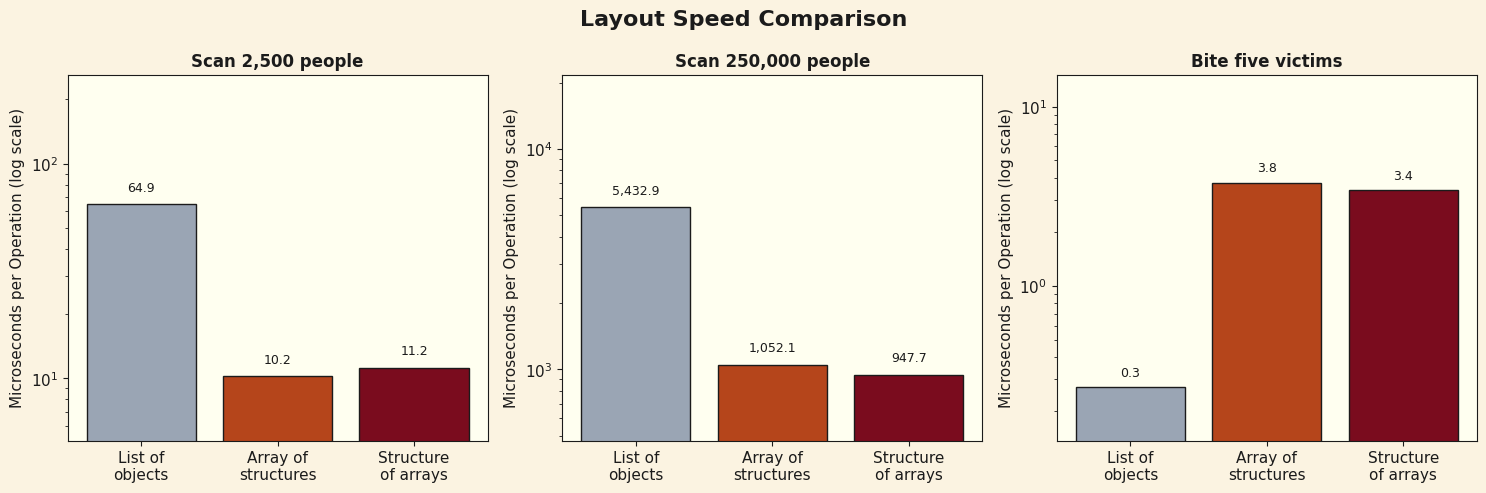

In [5]:
import timeit

class Person:
    __slots__ = ("pid", "cls", "bites", "last", "hunter")
    def __init__(self, pid, cls):
        self.pid, self.cls, self.bites, self.last, self.hunter = pid, cls, 0, 0, False

def make_town(N, seed=0):
    classes = np.random.default_rng(seed).integers(0, K, N)
    aos = np.zeros(N, dtype=[("pid", "i4"), ("cls", "i1"), ("bites", "i2"), ("last", "i4"), ("hunter", "?")])
    aos["pid"], aos["cls"] = np.arange(N), classes
    soa = {f: aos[f].copy() for f in aos.dtype.names}
    objs = [Person(i, int(c)) for i, c in enumerate(classes)]
    return objs, aos, soa

def scan_objs(objs):
    tot = cnt = 0
    for p in objs:
        if p.cls == 3:
            tot += p.bites; cnt += 1
    return tot / max(cnt, 1)
def scan_aos(aos): return aos["bites"][aos["cls"] == 3].mean()
def scan_soa(soa): return soa["bites"][soa["cls"] == 3].mean()

def upd_objs(objs, ids, night):
    for i in ids:
        p = objs[i]; p.bites += 1; p.last = night
def upd_aos(aos, ids, night):
    aos["bites"][ids] += 1; aos["last"][ids] = night
def upd_soa(soa, ids, night):
    soa["bites"][ids] += 1; soa["last"][ids] = night

def micros(fn, number):
    return min(timeit.repeat(fn, number=number, repeat=5)) / number * 1e6

LAYOUTS = ["List of objects", "Array of structures", "Structure of arrays"]
results = {}
for N, number in ((2500, 200), (250000, 3)):
    objs, aos, soa = make_town(N)
    results[f"Scan {N:,} people"] = [micros(lambda: scan_objs(objs), number),
                                     micros(lambda: scan_aos(aos), number),
                                     micros(lambda: scan_soa(soa), number)]
objs, aos, soa = make_town(2500)
ids = [5, 400, 1200, 1800, 2400]
results["Bite five victims"] = [micros(lambda: upd_objs(objs, ids, 7), 2000),
                                micros(lambda: upd_aos(aos, ids, 7), 2000),
                                micros(lambda: upd_soa(soa, ids, 7), 2000)]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, vals) in zip(axes, results.items()):
    bars = ax.bar(range(3), vals, color=[PALETTE["silver"], PALETTE["rust"], PALETTE["burgundy"]],
                  edgecolor=PALETTE["black"])
    ax.set_yscale("log")
    ax.set_ylim(min(vals) * 0.5, max(vals) * 4)
    ax.set_xticks(range(3)); ax.set_xticklabels(["List of\nobjects", "Array of\nstructures", "Structure\nof arrays"])
    ax.set_title(title, fontsize=12)
    ax.set_ylabel("Microseconds per Operation (log scale)")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.15, f"{v:,.1f}", ha="center", fontsize=9)
fig.suptitle("Layout Speed Comparison", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("10_layout_speed.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Build the bite archive

We simulate 250 vampires per strategy (1,500 lives total) and log every bite and every night. Mixing strategies gives the archive a realistic blend of victim classes, instead of being dominated by whoever the smartest vampire prefers.

In [6]:
R_ARCH, T_GAME = 250, 2500
archive = {name: simulate(pol, R_ARCH, T_GAME, seed=300 + i, hunter=True)
           for i, (name, pol) in enumerate(POLICIES.items())}

def tables_from(res, name, offset):
    y, alive, died, arm, dr = res["y"], res["alive"], res["died"], res["arm"], res["drained"]
    R, T = y.shape
    cs = np.concatenate([np.zeros((R, 1)), np.cumsum(y, axis=1)], axis=1)
    lag = np.maximum(np.arange(T) - 5, 0)
    recent = (cs[:, :T] - cs[:, lag]) / np.maximum(np.minimum(np.arange(T), 5), 1)   # avg of last 5 yields
    life = np.repeat(np.arange(R)[:, None] + offset, T, axis=1)
    night = np.tile(np.arange(T), (R, 1))
    nightly = pd.DataFrame({"life": life[alive], "night": night[alive], "drained": dr[alive],
                            "recent": recent[alive], "died": died[alive].astype(int)})
    bm = alive & ~died
    bites = pd.DataFrame({"life": life[bm], "night": night[bm], "cls": arm[bm].astype(int),
                          "yield_int": np.clip(np.rint(y[bm]), 0, 40).astype(int), "recent": recent[bm]})
    return nightly, bites

parts = [tables_from(res, nm, i * R_ARCH) for i, (nm, res) in enumerate(archive.items())]
nightly = pd.concat([p[0] for p in parts], ignore_index=True)
bites = pd.concat([p[1] for p in parts], ignore_index=True)
print(f"{len(bites):,} bites logged; {len(nightly):,} vampire-nights; {int(nightly['died'].sum()):,} deaths")

626,969 bites logged; 628,469 vampire-nights; 1,500 deaths


### Classifier A — Which victim was that?

Given a bite's yield (rounded to whole pints, so the Poisson classes' whole numbers aren't a giveaway), the night, and the recent average, can a **Random Forest** name the victim class? Some classes overlap heavily (Insomniac and Priest are both about 1 pint; Nurse and Sleepwalker both about 5), so there is a hard ceiling on accuracy. We compute that ceiling exactly from the true distributions (the best any classifier could do using the yield) and compare. Training and testing use different vampire lives.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score

feats = ["yield_int", "night", "recent"]
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(bites, groups=bites["life"]))
train = bites.iloc[tr].sample(min(200000, len(tr)), random_state=0)
test = bites.iloc[te]

rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=30, n_jobs=-1, random_state=0)
rf.fit(train[feats], train["cls"])
pred = rf.predict(test[feats])
acc = accuracy_score(test["cls"], pred)

# The best any classifier could do from the yield alone (Bayes-optimal accuracy)
rng = np.random.default_rng(1)
pmf = np.zeros((K, 41))
for c in range(K):
    d = draw_yield(np.full(400000, c), rng)
    pmf[c] = np.bincount(np.clip(np.rint(d), 0, 40).astype(int), minlength=41) / len(d)
prior = np.bincount(bites["cls"], minlength=K) / len(bites)
ceiling = (prior[:, None] * pmf).max(axis=0).sum()
majority = prior.max()

print(f"Random Forest accuracy: {acc:.1%}   |   ceiling: {ceiling:.1%}   |   always-guess-most-common: {majority:.1%}")

Random Forest accuracy: 63.9%   |   ceiling: 63.6%   |   always-guess-most-common: 56.4%


### Visual 11 — What gets confused with what

Each row is the true victim class; each cell shows how often the forest predicted that column. Dark cells off the diagonal are the overlaps the ceiling warned about: the classifier isn't failing there, the data genuinely can't tell those victims apart. The archive is dominated by College Students, so always guessing 'student' already scores well; the forest beats that baseline by a modest margin, and the footnote shows all three numbers.

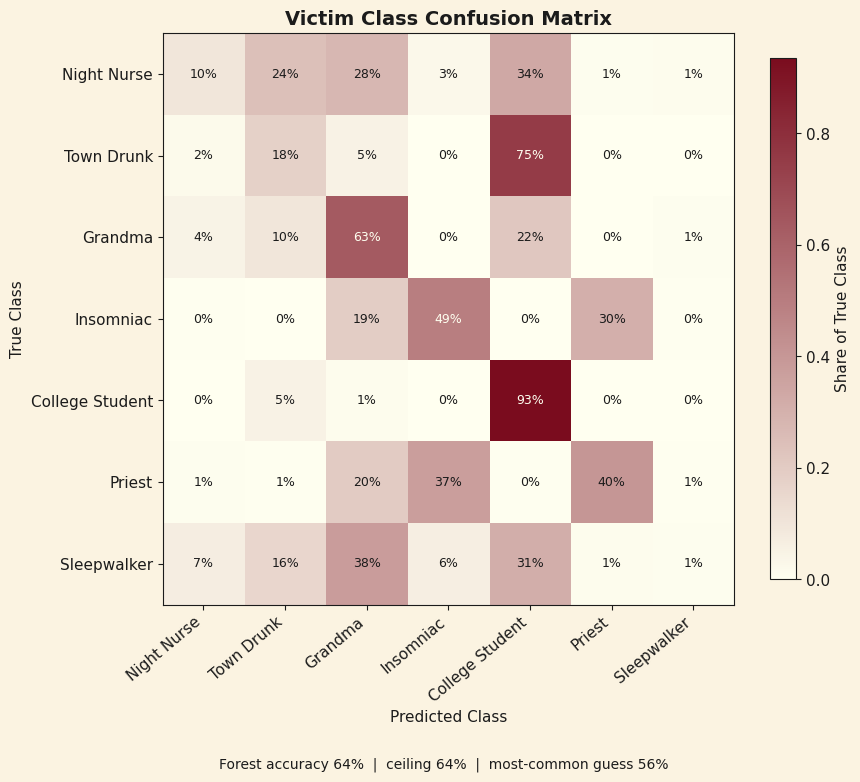

In [8]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("ivory_burgundy", [PALETTE["ivory"], PALETTE["burgundy"]])
cm = confusion_matrix(test["cls"], pred, labels=range(K), normalize="true")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap=cmap, vmin=0, vmax=max(cm.max(), 0.01))
ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=40, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color=PALETTE["ivory"] if cm[i, j] > 0.5 * cm.max() else PALETTE["black"])
ax.set_title("Victim Class Confusion Matrix")
fig.text(0.5, 0.01, f"Forest accuracy {acc:.0%}  |  ceiling {ceiling:.0%}  |  most-common guess {majority:.0%}",
         ha="center", fontsize=10)
plt.colorbar(im, label="Share of True Class", shrink=0.8)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("11_class_confusion.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Classifier B — How likely is the hunter tonight?

Now the rare event: out of about half a million vampire-nights, only 1,500 end with the hunter. The features are the night, blood drained so far, and the recent average yield. In truth the risk depends only on blood drained (through wariness), so the other two features are distractors the forest has to ignore. We don't use class weighting, because it would distort the probabilities we care about. And accuracy is useless here (always predicting 'safe' is 99.7% accurate), so we judge the model by **AUC** (ranking nights by danger) and by **calibration** (when it says 1%, does the hunter show up about 1% of the time?).

In [9]:
hz_feats = ["night", "drained", "recent"]
tr2, te2 = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=1).split(nightly, groups=nightly["life"]))
train2, test2 = nightly.iloc[tr2], nightly.iloc[te2]

rf2 = RandomForestClassifier(n_estimators=100, min_samples_leaf=5000, n_jobs=-1, random_state=0)
rf2.fit(train2[hz_feats], train2["died"])
risk = rf2.predict_proba(test2[hz_feats])[:, 1]
true_risk = np.minimum((1 + test2["drained"] / WARY_SCALE) / TOWN_SIZE, HAZARD_CAP)

auc_rf = roc_auc_score(test2["died"], risk)
auc_best = roc_auc_score(test2["died"], true_risk)
print(f"AUC: forest {auc_rf:.3f}   |   best possible (true hazard) {auc_best:.3f}")
print(f"Base rate of death per night: {test2['died'].mean():.3%}")

AUC: forest 0.669   |   best possible (true hazard) 0.669
Base rate of death per night: 0.238%


### Visual 12 — Is the risk estimate honest?

Nights are grouped into eight bins by predicted risk. Points show the predicted risk vs. how often the hunter actually appeared in that bin, with 95% error bars. Points on the diagonal mean the forest's probabilities can be taken at face value. Even a perfect model can only forecast a small chance, never a certainty — the hunter is rare and arrives by luck.

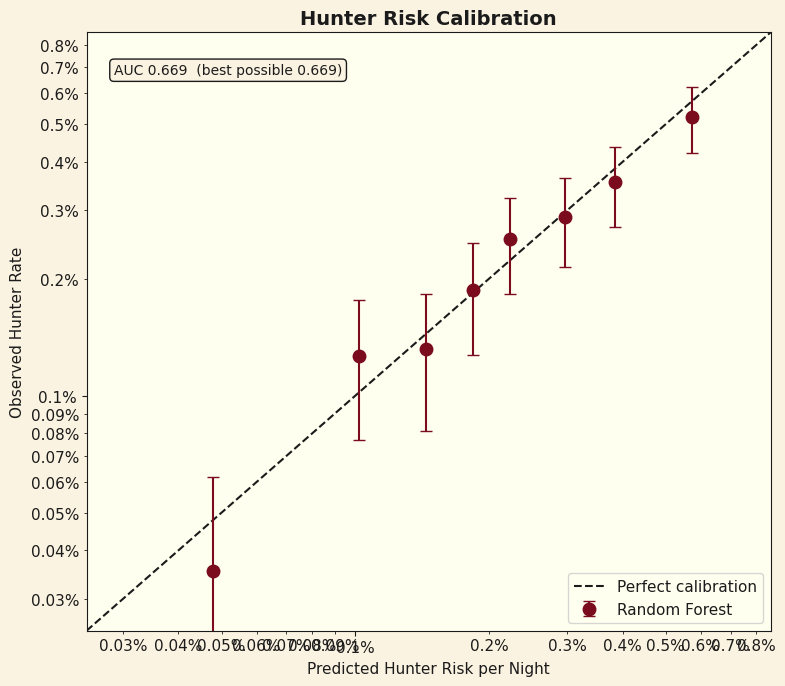

In [10]:
df = pd.DataFrame({"risk": risk, "died": test2["died"].values})
df["bin"] = pd.qcut(df["risk"], 8, duplicates="drop")
cal = df.groupby("bin", observed=True).agg(pred=("risk", "mean"), obs=("died", "mean"), n=("died", "size"))
cal["se"] = np.sqrt(cal["obs"] * (1 - cal["obs"]) / cal["n"])

fig, ax = plt.subplots(figsize=(8, 7))
lims = [min(cal["pred"].min(), cal["obs"].min()) * 0.7, max(cal["pred"].max(), cal["obs"].max()) * 1.5]
ax.plot(lims, lims, color=PALETTE["black"], linestyle="--", linewidth=1.5, label="Perfect calibration")
ax.errorbar(cal["pred"], cal["obs"], yerr=1.96 * cal["se"], fmt="o", color=PALETTE["burgundy"],
            ecolor=PALETTE["burgundy"], markersize=9, capsize=4, label="Random Forest")
from matplotlib.ticker import FuncFormatter
fmt = FuncFormatter(lambda v, _: f"{v * 100:.2g}%")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lims); ax.set_ylim(lims)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(fmt); axis.set_minor_formatter(fmt)
ax.set_xlabel("Predicted Hunter Risk per Night")
ax.set_ylabel("Observed Hunter Rate")
ax.set_title("Hunter Risk Calibration")
ax.text(0.04, 0.93, f"AUC {auc_rf:.3f}  (best possible {auc_best:.3f})", transform=ax.transAxes,
        fontsize=10, bbox=dict(boxstyle="round", facecolor=PALETTE["cream"], edgecolor=PALETTE["black"]))
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("12_hunter_risk_calibration.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### The series wraps here

Five weeks, five stochastic processes: Markov chains, Poisson processes, Brownian motion, Gibbs sampling, and Thompson Sampling — the last one the 'decide while you learn' idea behind recommendation systems, ad selection and A/B testing.